# Assignment 3 – Step response: single-storey two-zone office building (Chur)

**Team:** _Valerio Paganini_

This notebook uses the thermal circuit of Assignment 1 ([Assignment1_Model.ipynb](Assignment1_Model.ipynb)) and the
state-space representation of Assignment 2 ([Assignment2_SteadyState.ipynb](Assignment2_SteadyState.ipynb)).

Content, as in the list of the assignment:

1. time step and settling time,
2. input vector $u$,
3. integration in time of the differential equations,
4. plots of the results,
5. discussion of the results.

Two step responses are calculated:

- **Step 1 – free-floating building (test)**, as in 03CubicBuilding: controller off ($K_p = 0$), all temperatures
  0 °C at $t = 0$, then outdoor and basement temperature 10 °C. After the settling time every temperature must be
  10 °C.
- **Step 2 – controlled building, outdoor temperature step**: P-controller on ($K_p = 10^5$ W/K, set-point 21 °C),
  start from the steady state of the design case of Assignment 2 ($T_o = -7.2$ °C), then $T_o$ jumps to 10 °C. The
  basement temperature stays 0.96 °C (assumption: the basement reacts slowly). This shows how fast the heating load
  of the building follows the outdoor temperature.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dm4bem
from IPython.utils import io

with io.capture_output():                   # model (Assignment 1) and state space (Assignment 2), outputs not shown
    %run Assignment2_SteadyState.ipynb

states = np.flatnonzero(np.diag(C))         # nodes with capacity = state variables, in the order of the nodes
s_air = np.searchsorted(states, [air1, air2])
print(f'{len(states)} state variables, {len(u_names)} inputs, outputs θ{air1}, θ{air2} (air of zone 1 and 2)')

72 state variables, 48 inputs, outputs θ71, θ144 (air of zone 1 and 2)


## 1 Time step and settling time

The explicit Euler method is numerically stable if $|1 + \lambda_i \Delta t| < 1$ for all eigenvalues $\lambda_i$ of
$A_s$. The eigenvalues of a thermal circuit are real and negative, so the condition becomes

$$\Delta t < \Delta t_{max} = \min\left(-\frac{2}{\lambda_i}\right) = 2 \min T_i, \qquad T_i = -\frac{1}{\lambda_i}$$

where $T_i$ are the time constants. The settling time is about four times the largest time constant.

$A_s$ contains the gain $K_p$ of the controller, so both quantities are calculated for the two models. The table also
gives the state that dominates the fastest and the slowest mode (largest component of the eigenvector).

In [2]:
models = {'free-floating (K_p = 0)': cases['case 1: test']['ss'],
          'controlled (K_p = 1e5 W/K)': cases['case 2: design heating']['ss']}
tab = {}
for name, (As, Bs, Cs, Ds) in models.items():
    λ, V = np.linalg.eig(As)
    assert np.abs(λ.imag).max() < 1e-12 and λ.real.max() < 0     # real and negative
    λ, V = λ.real, V.real
    fast, slow = λ.argmin(), λ.argmax()
    tab[name] = {'smallest time constant (s)': -1 / λ[fast],
                 'fastest mode, mainly': node_name(states[np.abs(V[:, fast]).argmax()]),
                 'largest time constant (d)': -1 / λ[slow] / 86400,
                 'slowest mode, mainly': node_name(states[np.abs(V[:, slow]).argmax()]),
                 'Δt_max = 2 min T_i (s)': -2 / λ[fast],
                 'settling time 4 max T_i (d)': -4 / λ[slow] / 86400}
tab = pd.DataFrame(tab)
tab

,free-floating (K_p = 0),controlled (K_p = 1e5 W/K)
smallest time constant (s),515.333014,7.976548
"fastest mode, mainly",air zone 1,air zone 1
largest time constant (d),17.550996,7.864707
"slowest mode, mainly","floor zone 1, concrete 3","floor zone 2, concrete 2"
Δt_max = 2 min T_i (s),1030.666029,15.953096
settling time 4 max T_i (d),70.203984,31.458827


Choice of the time step. In every time step the explicit method multiplies each mode by $1 + \lambda_i \Delta t$:

| $\Delta t$ | $1 + \lambda_i \Delta t$ | explicit solution |
|---|---|---|
| $< T_{min}$ | between 0 and 1 | decays smoothly, like the exact solution |
| between $T_{min}$ and $2 T_{min} = \Delta t_{max}$ | between −1 and 0 | stable, but oscillates from one time step to the next |
| $> \Delta t_{max}$ | below −1 | unstable, grows without limit |

03CubicBuilding rounds $\Delta t_{max}$ down to whole minutes; here that gives a time step close to $\Delta t_{max}$ and
visible oscillations (see the end of section 3). The time step is therefore chosen below the smallest time constant
$T_{min}$:

- free-floating: $T_{min}$ = 515 s, rounded down to whole minutes;
- controlled: $T_{min}$ is only 8 s, because the controller couples the small capacity of the air strongly to the
  set-point ($T = C_{air} / (K_p + \sum G)$). It is rounded down to whole seconds.

The duration of each simulation is the settling time rounded up to whole hours.

In [3]:
T_min1, T_min2 = tab.loc['smallest time constant (s)']
dt1 = np.floor(T_min1 / 60) * 60
dt2 = np.floor(T_min2)
dur1, dur2 = (np.ceil(tab.loc['settling time 4 max T_i (d)'] * 24) * 3600).values
print(f'step 1 (free-floating): Δt = {dt1:.0f} s = {dt1 / 60:.0f} min, duration {dur1 / 86400:.1f} d, '
      f'{int(dur1 / dt1)} time steps')
print(f'step 2 (controlled):    Δt = {dt2:.0f} s, duration {dur2 / 86400:.1f} d, {int(dur2 / dt2)} time steps')

step 1 (free-floating): Δt = 480 s = 8 min, duration 70.2 d, 12637 time steps
step 2 (controlled):    Δt = 7 s, duration 31.5 d, 388800 time steps


## 2 Input vectors $u$

The order of the inputs is the one of Assignment 2: first the 20 temperature sources $b_T$ (order of the branches),
then the 28 flow-rate sources $f_Q$ (order of the nodes). For a step response every input is constant after $t = 0$,
so $u$ is the same for every time step.

| | step 1 | step 2, before $t = 0$ | step 2, after $t = 0$ |
|---|---|---|---|
| $K_p$ (W/K) | 0 | $10^5$ | $10^5$ |
| $T_o$ (°C) | 10 | −7.2 | **10** |
| $T_{bsmt}$ (°C) | 10 | 0.96 | 0.96 |
| $T_{sp}$ (°C) | 20 (no effect) | 21 | 21 |
| flow-rate sources (W) | 0 | 0 | 0 |
| initial state $\theta_C(0)$ | 0 °C | — | steady state before $t = 0$ |

In [4]:
def u_of(b_v, f_v):
    """Input vector u = [b_T, f_Q] from the vectors b and f (order of dm4bem.tc2ss)."""
    return np.hstack([b_v[b_ptr == 1], f_v[f_ptr == 1]])


u1 = u_of(*inputs(T_o=10, T_bsmt=10, T_sp=20))              # step 1
u2_0 = u_of(*inputs(T_o=T_o2, T_bsmt=T_bsmt2, T_sp=21))     # step 2 before t = 0 (case 2 of Assignment 2)
u2 = u_of(*inputs(T_o=10, T_bsmt=T_bsmt2, T_sp=21))         # step 2 after t = 0
pd.DataFrame({'step 1': u1, 'step 2, t < 0': u2_0, 'step 2, t ≥ 0': u2}, index=u_names).loc[lambda d: d.any(axis=1)]

,step 1,"step 2, t < 0","step 2, t ≥ 0"
b: q0 (T_o),10.0,-7.20,10.00
b: q15 (T_o),10.0,-7.20,10.00
b: q19 (T_o),10.0,-7.20,10.00
b: q34 (T_o),10.0,-7.20,10.00
b: q38 (T_o),10.0,-7.20,10.00
b: q53 (T_o),10.0,-7.20,10.00
b: q57 (T_o),10.0,-7.20,10.00
b: q72 (T_bsmt),10.0,0.96,0.96
b: q87 (T_o),10.0,-7.20,10.00
"b: q88 (T_sp,1)",20.0,21.00,21.00


## 3 Integration in time

Explicit (Euler forward) and implicit (Euler backward) integration:

$$\theta_{C,k+1} = (I + \Delta t A_s)\,\theta_{C,k} + \Delta t B_s u_k \qquad \text{(explicit)}$$

$$\theta_{C,k+1} = (I - \Delta t A_s)^{-1}(\theta_{C,k} + \Delta t B_s u_k) \qquad \text{(implicit)}$$

and the outputs $y_k = C_s \theta_{C,k} + D_s u_k$. The function returns the outputs and the states. The implicit
method is stable for any time step; it is also used with $\Delta t = 1$ h in step 2.

In [5]:
def simulate(ss, u, θ0, dt, duration, method='explicit', keep_states=False):
    """Step response with constant input u from the initial state θ0.

    Returns the time t (s), the outputs y (2 × n) and, if keep_states, the states θ (n_s × n)."""
    As, Bs, Cs, Ds = ss
    n = int(duration / dt) + 1
    I = np.eye(As.shape[0])
    if method == 'explicit':
        M, N = I + dt * As, dt * Bs @ u
    else:
        M = np.linalg.inv(I - dt * As)
        M, N = M, M @ (dt * Bs @ u)
    θ = np.zeros((As.shape[0], n)) if keep_states else None
    y = np.zeros((Cs.shape[0], n))
    θk = θ0.copy()
    for k in range(n):
        y[:, k] = Cs @ θk + Ds @ u
        if keep_states:
            θ[:, k] = θk
        θk = M @ θk + N
    return np.arange(n) * dt, y, θ

### Step 1 – free-floating building

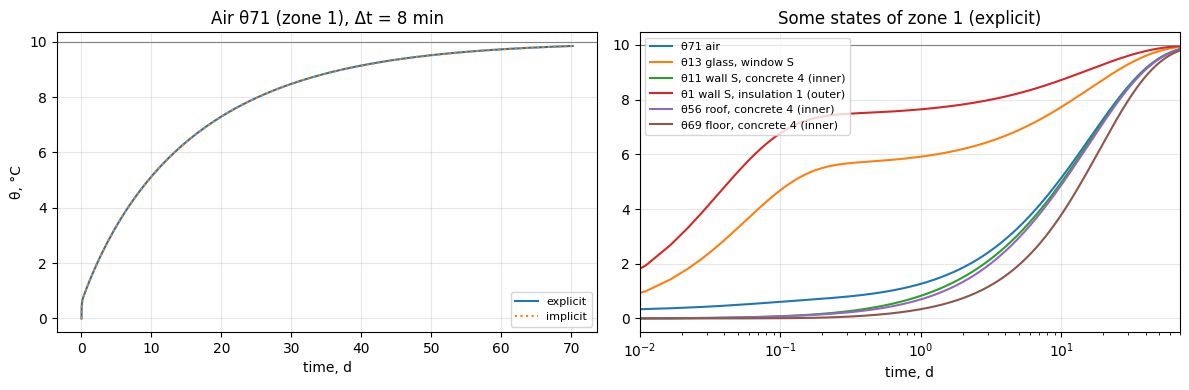

air θ71: 95 % of the step (9.5 °C) after 49.5 d; at the end 9.8462 °C (explicit), 9.8460 °C (implicit); steady state (Assignment 2) 10.0000 °C
max. difference explicit - implicit: 0.130 K


In [6]:
ss1 = models['free-floating (K_p = 0)']
θ0 = np.zeros(len(states))
t1, y1_exp, θ1_exp = simulate(ss1, u1, θ0, dt1, dur1, 'explicit', keep_states=True)
_, y1_imp, _ = simulate(ss1, u1, θ0, dt1, dur1, 'implicit')

show = {air1: 'air', 13: 'glass, window S', 11: 'wall S, concrete 4 (inner)', 1: 'wall S, insulation 1 (outer)',
        56: 'roof, concrete 4 (inner)', 69: 'floor, concrete 4 (inner)'}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(t1 / 86400, y1_exp[0], label='explicit')
axs[0].plot(t1 / 86400, y1_imp[0], ':', label='implicit')
axs[0].set(title=f'Air θ{air1} (zone 1), Δt = {dt1 / 60:.0f} min', xlabel='time, d', ylabel='θ, °C')
for i, lab in show.items():
    axs[1].plot(t1 / 86400, θ1_exp[np.searchsorted(states, i)], label=f'θ{i} {lab}')
axs[1].set(title='Some states of zone 1 (explicit)', xlabel='time, d', xscale='log', xlim=(1e-2, dur1 / 86400))
for ax in axs:
    ax.axhline(10, color='grey', lw=0.8)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

t95 = t1[np.argmax(y1_exp[0] >= 9.5)]
print(f'air θ{air1}: 95 % of the step (9.5 °C) after {t95 / 86400:.1f} d; '
      f'at the end {y1_exp[0, -1]:.4f} °C (explicit), {y1_imp[0, -1]:.4f} °C (implicit); steady state (Assignment 2) '
      f'{cases["case 1: test"]["y_ss"][0]:.4f} °C')
print(f'max. difference explicit - implicit: {np.abs(y1_exp - y1_imp).max():.3f} K')

### Step 2 – controlled building, outdoor temperature step

Initial state: the steady state before the step, $\theta_C(0) = -A_s^{-1} B_s u(t<0)$. The heat flow rate of the
P-controller is calculated from the output: $q_{HVAC} = K_p (T_{sp} - y)$.

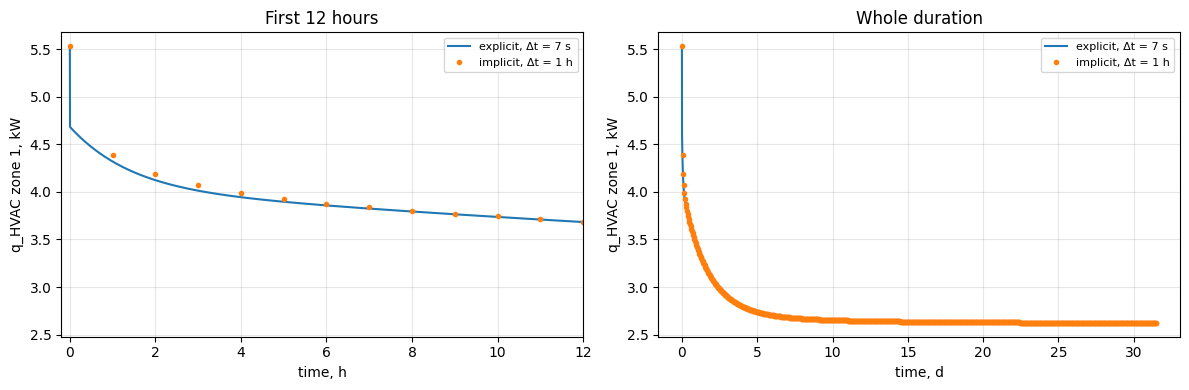

before the step      q_HVAC =    5533 W, air θ71 = 20.945 °C
after 1 time step    q_HVAC =    4788 W, air θ71 = 20.952 °C
after 15 min         q_HVAC =    4571 W, air θ71 = 20.954 °C
after 1 h            q_HVAC =    4320 W, air θ71 = 20.957 °C
after 1 d            q_HVAC =    3416 W, air θ71 = 20.966 °C
after 7 d            q_HVAC =    2681 W, air θ71 = 20.973 °C
at the end           q_HVAC =    2623 W, air θ71 = 20.974 °C
steady state after the step: q_HVAC = 2621 W; zone 2 equal to zone 1: True
share of the total drop of q_HVAC: 26% after 1 time step, 33% after 15 min, 42% after 1 h, 73% after 1 d, 98% after 7 d
ventilation alone: G_v ΔT_o = 862 W = 30% of the drop


In [7]:
ss2 = models['controlled (K_p = 1e5 W/K)']
As, Bs, Cs, Ds = ss2
K_p = 1e5
θ0 = -np.linalg.inv(As) @ Bs @ u2_0                           # steady state before the step
runs = {f'explicit, Δt = {dt2:.0f} s': simulate(ss2, u2, θ0, dt2, dur2, 'explicit'),
        'implicit, Δt = 1 h': simulate(ss2, u2, θ0, 3600, dur2, 'implicit')}
q = {name: K_p * (21 - y[0]) for name, (t, y, _) in runs.items()}   # W, zone 1

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for (name, (t, y, _)), kw in zip(runs.items(), (dict(), dict(ls='', marker='o', ms=3))):
    axs[0].plot(t / 3600, q[name] / 1000, label=name, **kw)
    axs[1].plot(t / 86400, q[name] / 1000, label=name, **kw)
axs[0].set(xlim=(-0.2, 12), title='First 12 hours', xlabel='time, h')
axs[1].set(title='Whole duration', xlabel='time, d')
for ax in axs:
    ax.set(ylabel='q_HVAC zone 1, kW')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

t, y, _ = runs[f'explicit, Δt = {dt2:.0f} s']
qe = q[f'explicit, Δt = {dt2:.0f} s']
q_end = K_p * (21 - (-Cs @ np.linalg.inv(As) @ Bs + Ds) @ u2)[0]   # steady state after the step
for label, tk in [('before the step', 0), ('after 1 time step', dt2), ('after 15 min', 900), ('after 1 h', 3600),
                  ('after 1 d', 86400),
                  ('after 7 d', 7 * 86400), ('at the end', t[-1])]:
    k = int(round(tk / dt2))
    print(f'{label:20s} q_HVAC = {qe[k]:7.0f} W, air θ{air1} = {y[0, k]:.3f} °C')
print(f'steady state after the step: q_HVAC = {q_end:.0f} W; zone 2 equal to zone 1: '
      f'{np.allclose(y[0], y[1])}')
print('share of the total drop of q_HVAC: ' + ', '.join(
    f'{(qe[0] - qe[int(round(tk / dt2))]) / (qe[0] - q_end):.0%} after {label}'
    for label, tk in [('1 time step', dt2), ('15 min', 900), ('1 h', 3600), ('1 d', 86400), ('7 d', 7 * 86400)]))
print(f'ventilation alone: G_v ΔT_o = {G_v * (10 - T_o2):.0f} W = {G_v * (10 - T_o2) / (qe[0] - q_end):.0%} of the drop')

### Time step of the explicit method

Step 2 with three time steps: below $T_{min}$ (chosen), between $T_{min}$ and $\Delta t_{max}$ (whole seconds
below $\Delta t_{max}$, as in 03CubicBuilding), and 5 % above $\Delta t_{max}$. The air temperature is shown for the
first four time steps and after 1 h.

In [8]:
dt_max2 = tab.loc['Δt_max = 2 min T_i (s)', 'controlled (K_p = 1e5 W/K)']
for dt in (dt2, np.floor(dt_max2), 1.05 * dt_max2):
    t, y, _ = simulate(ss2, u2, θ0, dt, 3600, 'explicit')
    print(f'Δt = {dt:4.1f} s = {dt / T_min2:.2f} T_min, 1 + λΔt = {1 - dt / T_min2:5.2f}: air '
          f'{", ".join(f"{v:.3f}" for v in y[0, :4])} … {y[0, -1]:.4g} °C after 1 h')

Δt =  7.0 s = 0.88 T_min, 1 + λΔt =  0.12: air 20.945, 20.952, 20.953, 20.953 … 20.96 °C after 1 h
Δt = 15.0 s = 1.88 T_min, 1 + λΔt = -0.88: air 20.945, 20.961, 20.947, 20.959 … 20.96 °C after 1 h
Δt = 16.8 s = 2.10 T_min, 1 + λΔt = -1.10: air 20.945, 20.962, 20.943, 20.964 … -5.932e+06 °C after 1 h


## 4 Discussion

- **Time step.** The fastest mode is the air in both models. Without controller its time constant is 515 s
  (air with ventilation and surfaces); the explicit method is stable up to 17 min, the chosen time step is 8 min.
  With the P-controller the time constant of the air is 8 s ($C_{air}/(K_p + \sum G)$): the explicit method needs a
  time step below 16 s, the chosen one is 7 s. With 15 s the solution oscillates from one time step to the next, with
  a time step 5 % above $\Delta t_{max}$ it diverges. The implicit method is stable for any time step: with
  $\Delta t$ = 1 h it gives the slow part of step 2 correctly, but not the first hour.
- **Settling time.** The largest time constant is 17.6 d without controller and 7.9 d with controller; the slowest
  mode is in the concrete of the floor above the basement. Four time constants give a settling time of 70 d and 31 d.
  The controller shortens the time constants because it fixes the air temperature.
- **Step 1 (free-floating).** All temperatures go to 10 °C, the steady state of Assignment 2 (case 1). At the end of
  the settling time the air is at 9.85 °C (98 % of the step), 95 % is reached after 50 d. The outer insulation mesh
  and the glass follow the outdoor temperature within hours, but only up to about 7.5 °C and 6 °C; the rest
  follows with the concrete, in days to weeks. The air is coupled more strongly to the concrete (through the inner
  surfaces) than to the outdoor air (ventilation), so it follows the slow concrete. Explicit and implicit solutions
  differ by at most 0.13 K.
- **Step 2 (controlled).** The air stays at 21 °C (deviation below 0.06 K), the controller takes the step. The
  heating load falls from 5.5 kW to 2.6 kW, the steady state for the new inputs. About a quarter of the drop is
  immediate (26 % after the first time step), mainly the ventilation, which has no capacity ($G_v \Delta T_o$ =
  0.86 kW, 30 % of the drop; part of it first goes into the surfaces). The windows follow within hours (42 % after
  1 h), the walls, the roof and the floor in days (73 % after 1 d, 98 % after 7 d), because the change of the outdoor
  temperature first has to pass the insulation and the concrete. Both zones respond in the same way.
- **Limits of the model.** The P-controller is ideal: unlimited power, heating and cooling, no dead-band. Step
  inputs are only a test; the response to weather (Assignment 4) needs time-varying inputs.